1. Подключение библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

Подключение библиотек:
- numpy и pandas - для математических вычислений, загрузки и обработки табличных данных
- matplotlib.pyplot и seaborn - для визуализации данных
- sklearn.model_selection - для разделения данных на обучающую и тестовую выборки
- sklearn.preprocessing - для масштабирования признаков
- sklearn.svm.SVC - для создания и обучения модели метода опорных векторов
- sklearn.metrics - для оценки качества моделей

2. Загрузка датасета, масштабирование признаков

In [2]:
df = pd.read_csv("bank.csv")

df["deposit"] = df["deposit"].map({"yes": 1, "no": 0})

X = df[["duration", "balance"]].values
y = df["deposit"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Данные успешно отмасштабированы. Первые 3 клиента (Длительность последнего звонка с клиентом, Баланс):")
print(np.round(X_train[:3], 2))

Данные успешно отмасштабированы. Первые 3 клиента (Длительность последнего звонка с клиентом, Баланс):
[[ 1.94  1.35]
 [-0.16 -0.37]
 [ 0.65 -0.42]]


В качестве двух самых важных признаков были выбраны сколько длился последний звонок у банка с клиентом и среднегодовой баланс клиента. Целевая переменная - взял ли клиент депозит. Признаки были отмасштабированы. На примере строки [1.94  1.35] - длительность последнего звонка 1,94 и баланс 1,35 значит, что этот клиент разговаривал с банком больше, чем в среднем разговаривали другие клиенты из датасета, и баланс выше среднего.

3. Обучение модели с линейным ядром

In [3]:
svm_linear = SVC(kernel="linear", C=1.0, gamma="scale", random_state=42)
svm_linear.fit(X_train, y_train)

y_pred_lin = svm_linear.predict(X_test)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность Линейного SVM: 71.3%


Здесь происходит обучение модели с линейным ядром с зазором C = 1.0. Точность модели 71,3% - это хорошая точность, модель хорошо предсказывает взял ли клиент депозит

In [4]:
svm_linear_small_C = SVC(kernel="linear", C=0.01, gamma="scale", random_state=42)
svm_linear_small_C.fit(X_train, y_train)

y_pred_small = svm_linear_small_C.predict(X_test)
acc_small = accuracy_score(y_test, y_pred_small)
print(f"Точность Линейного SVM (C=0.01): {acc_small*100:.1f}%")

Точность Линейного SVM (C=0.01): 71.2%


Здесь обучается линейная модель с зазором c = 0.01. Точность модели немного снизилась. Малое C создает более широкий зазор и допускает ошибки, позволяя одинаковым признакам оказаться по разные стороны разделяющей линии

In [5]:
svm_linear_big_C = SVC(kernel="linear", C=1000, gamma="scale", random_state=42)
svm_linear_big_C.fit(X_train, y_train)

y_pred_big = svm_linear_big_C.predict(X_test)
acc_big = accuracy_score(y_test, y_pred_big)
print(f"Точность Линейного SVM (C=1000): {acc_big*100:.1f}%")

Точность Линейного SVM (C=1000): 71.3%


Здесь обучается модель с зазором c = 1000. Точность модели не поменялась по сравнению с c=1. Большое C создает маленький зазор и старается правильно все признаки разделить, но это ведет к переобучению

4. Обучение модели с Гауссовым ядром (rbf)

In [6]:
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точность SVM (Ядро RBF): {acc_rbf*100:.1f}%")
print(f"Из {len(X_train)} обучающих примеров опорных векторов - {len(svm_rbf.support_vectors_)}")

Точность SVM (Ядро RBF): 72.4%
Из 8929 обучающих примеров опорных векторов - 5088


Здесь обучается модель с ядром RBF. Точность модели 72,4%, это немного выше, чем точность модели с линейным ядром. Из 8929 обучающих примеров опорных векторов модель выбрала 5088 - это значит, что признаки непросто разделить линией, граница между клиентами взявшими депозит и не взявшими не явная. 5088 / 8929 = 0,57, т.е. 57% от всей обучающей выборки составляют опорные вектора

5. Визуализация

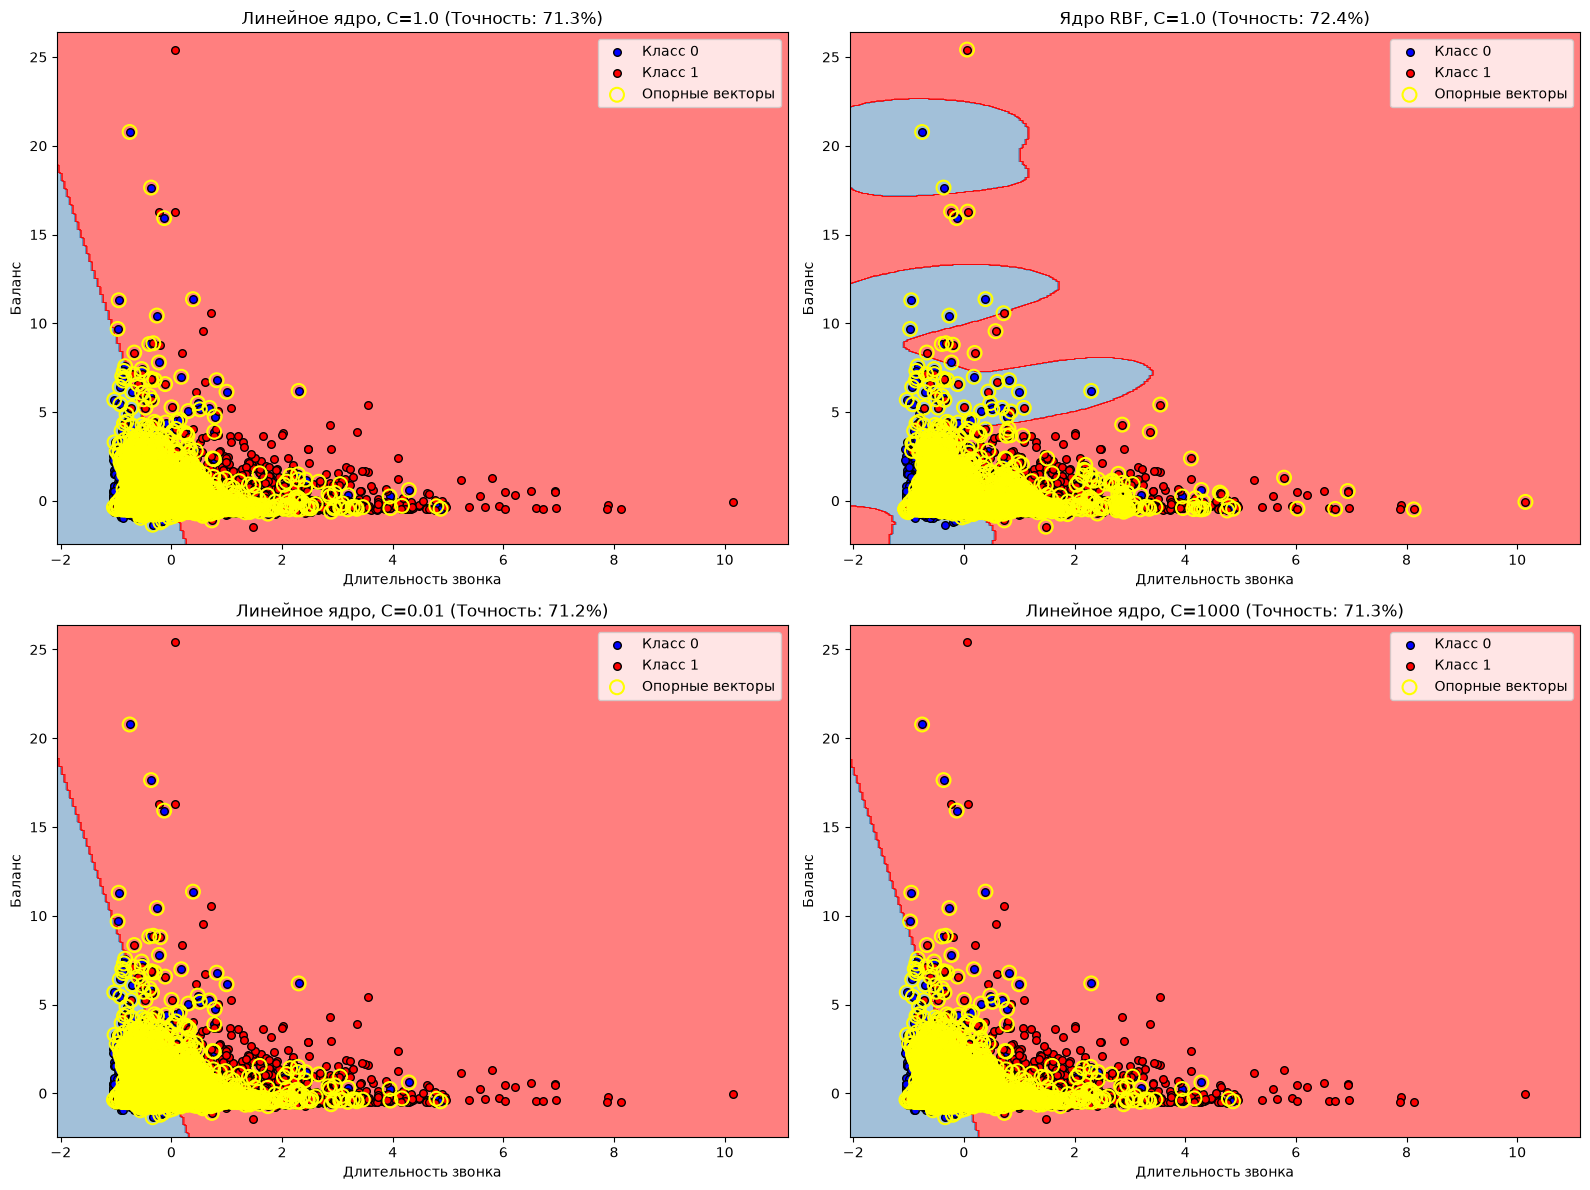

In [7]:
def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train, y_train
    X1, X2 = np.meshgrid(
        np.arange(
            start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.05
        ),
        np.arange(
            start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.05
        ),
    )
    ax.contourf(
        X1,
        X2,
        model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "red")),
    )

    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            label=f"Класс {j}",
            edgecolors="k",
            s=30,
        )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="yellow",
        s=100,
        linewidth=1.5,
        label="Опорные векторы",
    )

    ax.set_title(title)
    ax.set_xlabel("Длительность звонка")
    ax.set_ylabel("Баланс")
    ax.legend()
    
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

plot_decision_boundary(
    svm_linear, axes[0, 0], f"Линейное ядро, C=1.0 (Точность: {acc_lin*100:.1f}%)"
)
plot_decision_boundary(
    svm_rbf, axes[0, 1], f"Ядро RBF, C=1.0 (Точность: {acc_rbf*100:.1f}%)"
)
plot_decision_boundary(
    svm_linear_small_C, axes[1, 0], f"Линейное ядро, C=0.01 (Точность: {acc_small*100:.1f}%)"
)
plot_decision_boundary(
    svm_linear_big_C, axes[1, 1], f"Линейное ядро, C=1000 (Точность: {acc_big*100:.1f}%)"
)

plt.tight_layout()
plt.show()

Поскольку точность линейной модели при разных C изменилась очень незначительно, то на графиках тоже изменения незаметны. У модели с ядром Гаусса точность выше, поэтому на графике видно, что она добавила еще область для разделения признаков